# Comparative Evaluation of CK and Structural Software Metrics for Machine Learning-Based Design Pattern Detection

This notebook is the revised experimental notebook for the article.

## Main goal
Compare three feature configurations under the **same data, folds, classifiers, random seed, and evaluation metrics**:

1. **Structural only** — the original hand-engineered structural code metrics.
2. **CK only** — WMC, DIT, NOC, CBO, RFC, and LCOM1.
3. **Structural + CK** — the union of both feature groups.

## Research questions
- **RQ1:** How effective are CK metrics for machine learning-based design pattern detection?
- **RQ2:** How do CK metrics compare with the original structural software metrics?
- **RQ3:** Does combining CK and structural metrics improve classification performance?
- **RQ4:** Which CK metrics contribute most to the prediction of design patterns?

> Important: Missing target labels are excluded by default. Explicit `Unknown` labels are retained.


## 1. Environment and Google Drive
The notebook assumes that all files are stored in:

`/content/drive/MyDrive/hybrid/`

Required input:
- `df_hybrid_with_CK_master.csv`

The notebook writes all article results to:
- `/content/drive/MyDrive/hybrid/article_results_ck_comparison/`


In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
# Core imports
from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    make_scorer,
    classification_report,
    ConfusionMatrixDisplay,
)
from sklearn.inspection import permutation_importance

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_SPLITS = 5

BASE_DIR = Path("/content/drive/MyDrive/hybrid")
MASTER_FILE = BASE_DIR / "df_hybrid_with_CK_master.csv"
RESULTS_DIR = BASE_DIR / "article_results_ck_comparison"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Input:", MASTER_FILE)
print("Results:", RESULTS_DIR)


Input: /content/drive/MyDrive/hybrid/df_hybrid_with_CK_master.csv
Results: /content/drive/MyDrive/hybrid/article_results_ck_comparison


## 2. Load the merged master dataset

This dataset contains the original features plus the CK metrics added from the Java source-code analysis.


In [3]:
data = pd.read_csv(MASTER_FILE, low_memory=False)

print("Shape:", data.shape)
print("\nTarget distribution including missing values:")
display(data["DesignPattern"].value_counts(dropna=False).to_frame("count"))

required_ck = ["CK_WMC", "CK_DIT", "CK_NOC", "CK_CBO", "CK_RFC", "CK_LCOM1"]
missing_cols = [c for c in required_ck if c not in data.columns]
if missing_cols:
    raise ValueError(f"Missing CK columns: {missing_cols}")

if "CK_MergeMatched" in data.columns:
    print("\nCK merge status:")
    display(data["CK_MergeMatched"].value_counts(dropna=False).to_frame("count"))


Shape: (2303, 343)

Target distribution including missing values:


,count
DesignPattern,
Strategy,292
AbstractFactory,240
FactoryMethod,218
Visitor,191
Adapter,189
Prototype,151
Decorator,146
Memento,139
Observer,138



CK merge status:


,count
CK_MergeMatched,
True,2302
False,1


## 3. Data-quality policy

For the main experiment:
- rows without a known target label are excluded;
- explicit `Unknown` is retained as a valid negative/other class;
- only rows successfully matched with CK data are used;
- rows with serious parse failure are excluded.

`DITResolved` is **not required** in the primary analysis because external parent classes may be outside the archived corpus. A sensitivity analysis for fully resolved DIT rows is provided later.


In [4]:
# Preserve explicit Unknown, but do not convert missing labels into Unknown.
exp = data.copy()
exp = exp[exp["DesignPattern"].notna()].copy()

# Keep only successfully merged CK rows when the column exists.
if "CK_MergeMatched" in exp.columns:
    matched = exp["CK_MergeMatched"].astype(str).str.lower().isin(["true", "1"])
    exp = exp[matched].copy()

# Exclude rows with serious parse failure.
if "CK_ParseStatus" in exp.columns:
    # "OK" is preferred; PARSE_WARN_* rows can be excluded for reproducibility.
    exp = exp[exp["CK_ParseStatus"].astype(str).eq("OK")].copy()

print("Rows used in the primary experiment:", len(exp))
print("Number of target classes:", exp["DesignPattern"].nunique())
display(exp["DesignPattern"].value_counts().to_frame("count"))

# Save the exact experimental population for reproducibility.
exp.to_csv(RESULTS_DIR / "experimental_population.csv", index=False)


Rows used in the primary experiment: 2210
Number of target classes: 14


,count
DesignPattern,
Strategy,292
AbstractFactory,239
FactoryMethod,218
Visitor,191
Adapter,188
Prototype,151
Decorator,146
Memento,139
Observer,138


## 4. Feature sets

The comparison must differ **only in the feature representation**.  
The target rows, folds, classifiers, and random seed are held constant.


In [5]:
STRUCTURAL_FEATURES = [
    "Abstract",
    "Final",
    "Interfaces",
    "TotalAttributes",
    "PrivateAttributes",
    "ProtectedAttributes",
    "PublicAttributes",
    "StaticAttributes",
    "ObjectAttributes",
    "CollectionAttributes",
    "TotalMethods",
    "PublicMethods",
    "PrivateMethods",
    "ProtectedMethods",
    "StaticMethods",
    "OverloadedMethods",
    "OverriddenMethods",
    "GetterSetterCount",
    "AvgMethodLength",
    "CyclomaticComplexity",
]

CK_FEATURES = [
    "CK_WMC",
    "CK_DIT",
    "CK_NOC",
    "CK_CBO",
    "CK_RFC",
    "CK_LCOM1",
]

# Check that all selected features are available.
for c in STRUCTURAL_FEATURES + CK_FEATURES:
    if c not in exp.columns:
        raise ValueError(f"Required feature is missing: {c}")

FEATURE_SETS = {
    "Structural only": STRUCTURAL_FEATURES,
    "CK only": CK_FEATURES,
    "Structural + CK": STRUCTURAL_FEATURES + CK_FEATURES,
}

for name, cols in FEATURE_SETS.items():
    print(f"{name:18s}: {len(cols)} features")


Structural only   : 20 features
CK only           : 6 features
Structural + CK   : 26 features


## 5. Prepare X and y

All features are converted to numeric values. Missing feature values are handled inside each ML pipeline using median imputation, avoiding information leakage.


In [6]:
y = exp["DesignPattern"].astype(str).copy()

X_sets = {}
for name, cols in FEATURE_SETS.items():
    X_sets[name] = exp[cols].apply(pd.to_numeric, errors="coerce").copy()

print("Target classes:")
print(sorted(y.unique()))
print("\nMinimum samples in a class:", y.value_counts().min())


Target classes:
['AbstractFactory', 'Adapter', 'Builder', 'Decorator', 'Facade', 'FactoryMethod', 'Memento', 'Observer', 'Prototype', 'Proxy', 'Singleton', 'Strategy', 'Unknown', 'Visitor']

Minimum samples in a class: 68


## 6. Machine-learning models

The same models are applied to each feature set.

- Random Forest: nonlinear tree ensemble.
- SVM (RBF): nonlinear margin-based classifier.
- Logistic Regression: linear baseline.
- Gradient Boosting: nonlinear boosting baseline.
- MLP: neural-network baseline.

Scaling is applied to all models for a consistent pipeline; it is harmless for tree-based models.


In [7]:
def make_pipeline(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model),
    ])

MODELS = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1,
    ),
    "SVM (RBF)": SVC(
        kernel="rbf",
        class_weight="balanced",
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE,
    ),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(128, 64),
        max_iter=2000,
        early_stopping=False,
        random_state=RANDOM_STATE,
    ),
}

pipelines = {name: make_pipeline(model) for name, model in MODELS.items()}
print("Models:", list(pipelines))


Models: ['Random Forest', 'SVM (RBF)', 'Logistic Regression', 'Gradient Boosting', 'MLP']


### Note on MLP configuration

`early_stopping=False` is intentional. With multiclass imbalanced data, scikit-learn's internal validation split used by `early_stopping=True` can fail when some design-pattern classes are too small for the internal split. The outer 5-fold Stratified Cross-Validation remains unchanged and is the evaluation protocol used in the article.


## 7. Evaluation protocol

A **5-fold Stratified Cross-Validation** is used.

Reported metrics:
- Accuracy
- Macro Precision
- Macro Recall
- Macro F1
- Training time
- Inference/scoring time

Macro metrics are emphasized because the design-pattern classes are imbalanced.


In [8]:
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
    "f1_macro": make_scorer(f1_score, average="macro", zero_division=0),
}

summary_rows = []
fold_rows = []

for feature_name, X in X_sets.items():
    print(f"\n=== {feature_name} ===")

    for model_name, pipeline in pipelines.items():
        result = cross_validate(
            pipeline,
            X,
            y,
            cv=cv,
            scoring=scoring,
            return_train_score=False,
            n_jobs=-1,
        )

        row = {
            "FeatureSet": feature_name,
            "Model": model_name,
            "Accuracy_mean": result["test_accuracy"].mean(),
            "Accuracy_std": result["test_accuracy"].std(),
            "Precision_macro_mean": result["test_precision_macro"].mean(),
            "Precision_macro_std": result["test_precision_macro"].std(),
            "Recall_macro_mean": result["test_recall_macro"].mean(),
            "Recall_macro_std": result["test_recall_macro"].std(),
            "F1_macro_mean": result["test_f1_macro"].mean(),
            "F1_macro_std": result["test_f1_macro"].std(),
            "Fit_time_mean_sec": result["fit_time"].mean(),
            "Score_time_mean_sec": result["score_time"].mean(),
        }
        summary_rows.append(row)

        for fold_i in range(N_SPLITS):
            fold_rows.append({
                "FeatureSet": feature_name,
                "Model": model_name,
                "Fold": fold_i + 1,
                "Accuracy": result["test_accuracy"][fold_i],
                "Precision_macro": result["test_precision_macro"][fold_i],
                "Recall_macro": result["test_recall_macro"][fold_i],
                "F1_macro": result["test_f1_macro"][fold_i],
                "Fit_time_sec": result["fit_time"][fold_i],
                "Score_time_sec": result["score_time"][fold_i],
            })

        print(
            f"{model_name:22s} "
            f"Acc={row['Accuracy_mean']:.4f} "
            f"Macro-F1={row['F1_macro_mean']:.4f}"
        )

results = pd.DataFrame(summary_rows)
fold_results = pd.DataFrame(fold_rows)

results = results.sort_values(
    ["F1_macro_mean", "Accuracy_mean"],
    ascending=False,
).reset_index(drop=True)

display(results)

results.to_csv(RESULTS_DIR / "comparison_summary.csv", index=False)
fold_results.to_csv(RESULTS_DIR / "comparison_per_fold.csv", index=False)



=== Structural only ===
Random Forest          Acc=0.5507 Macro-F1=0.5289
SVM (RBF)              Acc=0.3742 Macro-F1=0.3474
Logistic Regression    Acc=0.3321 Macro-F1=0.3072
Gradient Boosting      Acc=0.5149 Macro-F1=0.4829
MLP                    Acc=0.5344 Macro-F1=0.5038

=== CK only ===
Random Forest          Acc=0.5946 Macro-F1=0.5463
SVM (RBF)              Acc=0.3303 Macro-F1=0.2524
Logistic Regression    Acc=0.1914 Macro-F1=0.1299
Gradient Boosting      Acc=0.5733 Macro-F1=0.5200
MLP                    Acc=0.5638 Macro-F1=0.5135

=== Structural + CK ===
Random Forest          Acc=0.7054 Macro-F1=0.6605
SVM (RBF)              Acc=0.3995 Macro-F1=0.3852
Logistic Regression    Acc=0.3602 Macro-F1=0.3455
Gradient Boosting      Acc=0.6710 Macro-F1=0.6160
MLP                    Acc=0.6597 Macro-F1=0.6021


,FeatureSet,Model,Accuracy_mean,Accuracy_std,Precision_macro_mean,Precision_macro_std,Recall_macro_mean,Recall_macro_std,F1_macro_mean,F1_macro_std,Fit_time_mean_sec,Score_time_mean_sec
0,Structural + CK,Random Forest,0.705430,0.020307,0.672458,0.027503,0.663852,0.022779,0.660500,0.023567,1.758407,0.139745
1,Structural + CK,Gradient Boosting,0.671041,0.028098,0.637443,0.036578,0.619212,0.024587,0.616032,0.024423,8.227125,0.039507
2,Structural + CK,MLP,0.659729,0.019176,0.614496,0.022370,0.604507,0.019330,0.602082,0.019232,12.174079,0.031415
3,CK only,Random Forest,0.594570,0.018624,0.578926,0.023347,0.553632,0.014897,0.546313,0.016456,1.905094,0.143391
4,Structural only,Random Forest,0.550679,0.014494,0.555224,0.027936,0.533009,0.016602,0.528943,0.020464,1.924877,0.159102
5,CK only,Gradient Boosting,0.573303,0.029346,0.564372,0.041520,0.522125,0.027379,0.520007,0.029091,5.263605,0.038548
6,CK only,MLP,0.563801,0.026937,0.555924,0.029752,0.518091,0.024399,0.513505,0.025118,22.939428,0.030032
7,Structural only,MLP,0.534389,0.019325,0.527440,0.022418,0.506743,0.019581,0.503838,0.020330,13.356244,0.031528
8,Structural only,Gradient Boosting,0.514932,0.021540,0.510119,0.028070,0.488236,0.023713,0.482926,0.025278,6.585475,0.041241
9,Structural + CK,SVM (RBF),0.399548,0.030239,0.449179,0.043527,0.412112,0.022381,0.385192,0.031269,0.426746,0.141409


## 8. Best configuration and article-ready ranking


In [9]:
best = results.iloc[0]

print("Best result:")
print("Feature set :", best["FeatureSet"])
print("Model       :", best["Model"])
print("Accuracy    :", round(best["Accuracy_mean"], 4))
print("Macro-F1    :", round(best["F1_macro_mean"], 4))

article_table = results[
    [
        "FeatureSet",
        "Model",
        "Accuracy_mean",
        "Accuracy_std",
        "Precision_macro_mean",
        "Recall_macro_mean",
        "F1_macro_mean",
        "F1_macro_std",
        "Fit_time_mean_sec",
    ]
].copy()

display(article_table)
article_table.to_csv(RESULTS_DIR / "article_results_table.csv", index=False)


Best result:
Feature set : Structural + CK
Model       : Random Forest
Accuracy    : 0.7054
Macro-F1    : 0.6605


,FeatureSet,Model,Accuracy_mean,Accuracy_std,Precision_macro_mean,Recall_macro_mean,F1_macro_mean,F1_macro_std,Fit_time_mean_sec
0,Structural + CK,Random Forest,0.705430,0.020307,0.672458,0.663852,0.660500,0.023567,1.758407
1,Structural + CK,Gradient Boosting,0.671041,0.028098,0.637443,0.619212,0.616032,0.024423,8.227125
2,Structural + CK,MLP,0.659729,0.019176,0.614496,0.604507,0.602082,0.019232,12.174079
3,CK only,Random Forest,0.594570,0.018624,0.578926,0.553632,0.546313,0.016456,1.905094
4,Structural only,Random Forest,0.550679,0.014494,0.555224,0.533009,0.528943,0.020464,1.924877
5,CK only,Gradient Boosting,0.573303,0.029346,0.564372,0.522125,0.520007,0.029091,5.263605
6,CK only,MLP,0.563801,0.026937,0.555924,0.518091,0.513505,0.025118,22.939428
7,Structural only,MLP,0.534389,0.019325,0.527440,0.506743,0.503838,0.020330,13.356244
8,Structural only,Gradient Boosting,0.514932,0.021540,0.510119,0.488236,0.482926,0.025278,6.585475
9,Structural + CK,SVM (RBF),0.399548,0.030239,0.449179,0.412112,0.385192,0.031269,0.426746


## 9. Visual comparison: Macro-F1

The plot uses mean Macro-F1 from the same stratified folds.


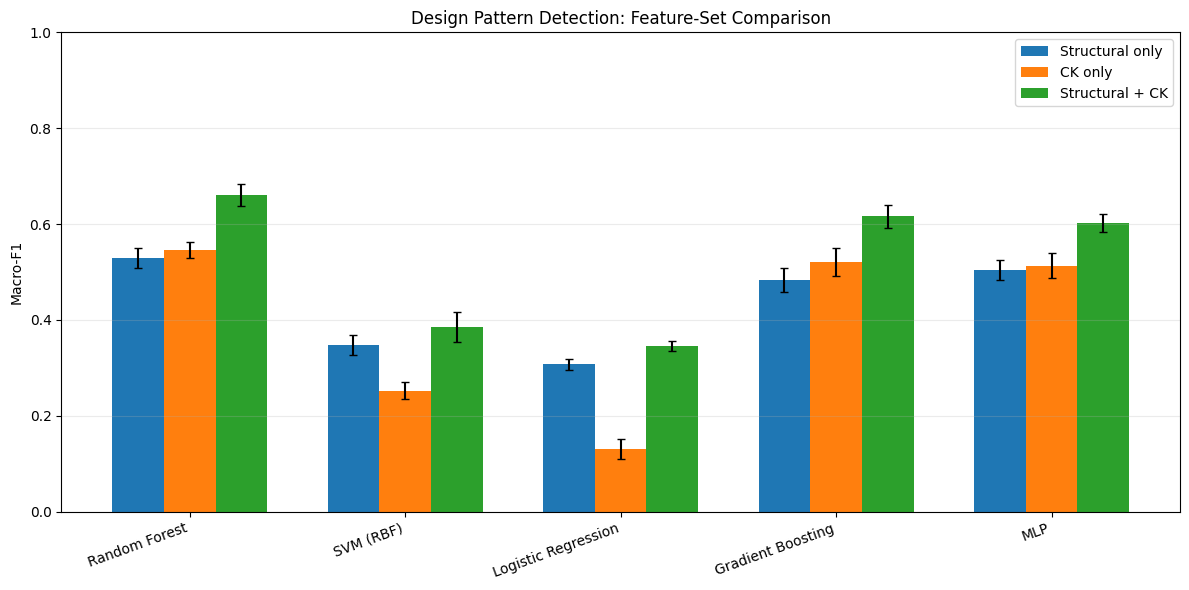

In [10]:
plot_df = results.copy()

fig, ax = plt.subplots(figsize=(12, 6))

feature_order = ["Structural only", "CK only", "Structural + CK"]
model_order = list(MODELS.keys())
x = np.arange(len(model_order))
width = 0.24

for i, feature_set in enumerate(feature_order):
    subset = (
        plot_df[plot_df["FeatureSet"] == feature_set]
        .set_index("Model")
        .reindex(model_order)
    )
    ax.bar(
        x + (i - 1) * width,
        subset["F1_macro_mean"],
        width,
        label=feature_set,
        yerr=subset["F1_macro_std"],
        capsize=3,
    )

ax.set_ylabel("Macro-F1")
ax.set_title("Design Pattern Detection: Feature-Set Comparison")
ax.set_xticks(x)
ax.set_xticklabels(model_order, rotation=20, ha="right")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "macro_f1_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


## 10. CK feature importance

Permutation importance is calculated for the CK-only configuration using Random Forest on a fixed stratified hold-out set.

This analysis supports **RQ4: Which CK metrics contribute most to design-pattern classification?**


,Metric,Importance_mean,Importance_std
3,CK_CBO,0.318530,0.013881
4,CK_RFC,0.309211,0.012998
0,CK_WMC,0.226526,0.017057
5,CK_LCOM1,0.177779,0.016958
1,CK_DIT,0.139984,0.012532
2,CK_NOC,0.004888,0.002317


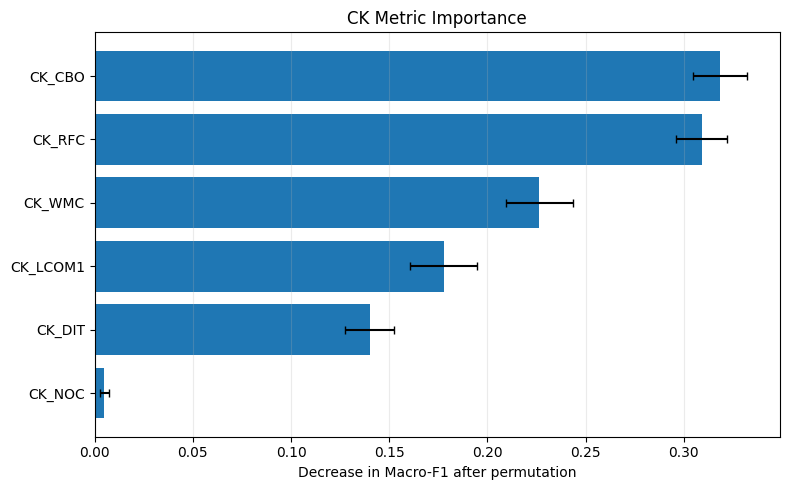

In [12]:
from sklearn.inspection import permutation_importance

X_ck = X_sets["CK only"]

X_train, X_test, y_train, y_test = train_test_split(
    X_ck,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

ck_rf = clone(pipelines["Random Forest"])
ck_rf.fit(X_train, y_train)

perm = permutation_importance(
    ck_rf,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=20,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

importance = pd.DataFrame({
    "Metric": CK_FEATURES,
    "Importance_mean": perm.importances_mean,
    "Importance_std": perm.importances_std,
}).sort_values("Importance_mean", ascending=False)

display(importance)

importance.to_csv(
    RESULTS_DIR / "ck_permutation_importance.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(8, 5))

imp_plot = importance.sort_values("Importance_mean")

ax.barh(
    imp_plot["Metric"],
    imp_plot["Importance_mean"],
    xerr=imp_plot["Importance_std"],
    capsize=3,
)

ax.set_xlabel("Decrease in Macro-F1 after permutation")
ax.set_title("CK Metric Importance")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "ck_feature_importance.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 11. Detailed classification report for the best configuration

A fixed stratified 80/20 split is used only for an interpretable class-level report.  
The main article comparison remains the 5-fold cross-validation above.


In [13]:
best_feature_set = best["FeatureSet"]
best_model_name = best["Model"]

X_best = X_sets[best_feature_set]

X_train, X_test, y_train, y_test = train_test_split(
    X_best,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

best_pipeline = clone(pipelines[best_model_name])
best_pipeline.fit(X_train, y_train)
y_pred = best_pipeline.predict(X_test)

report_dict = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0,
)
report_df = pd.DataFrame(report_dict).T
display(report_df)

report_df.to_csv(RESULTS_DIR / "best_model_classification_report.csv")

print(
    f"Hold-out accuracy: {accuracy_score(y_test, y_pred):.4f}\n"
    f"Hold-out Macro-F1: {f1_score(y_test, y_pred, average='macro'):.4f}"
)


,precision,recall,f1-score,support
AbstractFactory,0.811321,0.895833,0.851485,48.000000
Adapter,0.771429,0.729730,0.750000,37.000000
Builder,0.608696,0.583333,0.595745,24.000000
Decorator,0.720000,0.620690,0.666667,29.000000
Facade,0.760000,0.730769,0.745098,26.000000
FactoryMethod,0.634146,0.590909,0.611765,44.000000
Memento,0.840000,0.750000,0.792453,28.000000
Observer,0.611111,0.785714,0.687500,28.000000
Prototype,0.550000,0.733333,0.628571,30.000000
Proxy,0.230769,0.214286,0.222222,14.000000


Hold-out accuracy: 0.6923
Hold-out Macro-F1: 0.6424


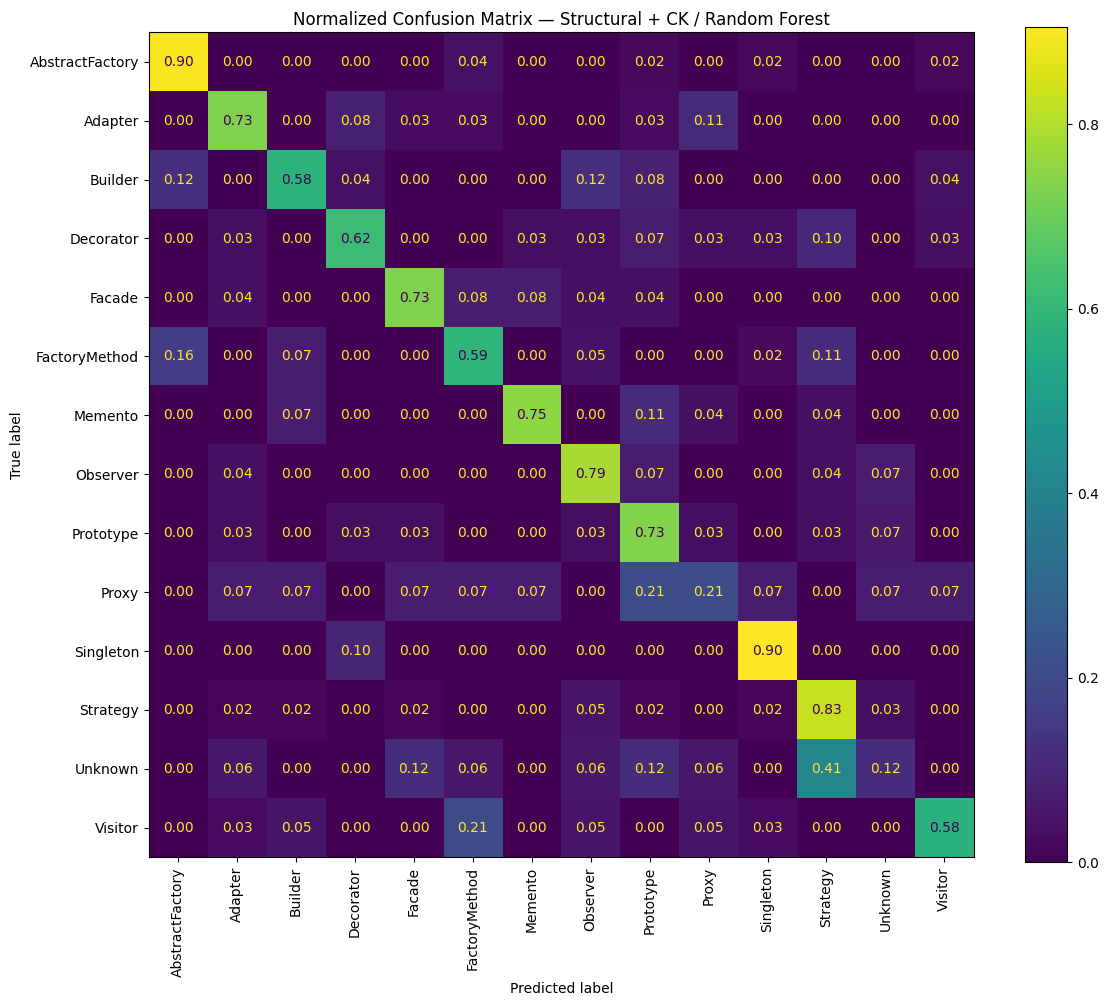

In [14]:
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=sorted(y.unique()),
    normalize="true",
    xticks_rotation=90,
    cmap=None,
    ax=ax,
    values_format=".2f",
)
ax.set_title(f"Normalized Confusion Matrix — {best_feature_set} / {best_model_name}")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "best_model_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


## 12. Sensitivity analysis: resolved DIT only

Because DIT can depend on parent classes outside the archived source corpus, this section repeats the comparison on rows for which the DIT chain is fully resolved.

Use this analysis as a robustness check, not as a replacement for the primary result.


In [15]:
if "CK_DITResolved" in exp.columns:
    resolved_mask = exp["CK_DITResolved"].astype(str).str.lower().isin(["true", "1"])
    exp_resolved = exp[resolved_mask].copy()

    print("Rows with fully resolved DIT:", len(exp_resolved))
    print("Classes:", exp_resolved["DesignPattern"].nunique())

    y_r = exp_resolved["DesignPattern"].astype(str)
    sensitivity_rows = []

    # Use the two most interpretable/representative classifiers to keep runtime reasonable.
    sensitivity_models = {
        "Random Forest": pipelines["Random Forest"],
        "Logistic Regression": pipelines["Logistic Regression"],
    }

    for feature_name, cols in FEATURE_SETS.items():
        X_r = exp_resolved[cols].apply(pd.to_numeric, errors="coerce")
        for model_name, pipe in sensitivity_models.items():
            r = cross_validate(
                pipe,
                X_r,
                y_r,
                cv=cv,
                scoring=scoring,
                n_jobs=-1,
            )
            sensitivity_rows.append({
                "FeatureSet": feature_name,
                "Model": model_name,
                "Rows": len(exp_resolved),
                "Accuracy_mean": r["test_accuracy"].mean(),
                "F1_macro_mean": r["test_f1_macro"].mean(),
            })

    sensitivity = pd.DataFrame(sensitivity_rows).sort_values(
        "F1_macro_mean",
        ascending=False,
    )
    display(sensitivity)
    sensitivity.to_csv(
        RESULTS_DIR / "sensitivity_resolved_DIT.csv",
        index=False,
    )
else:
    print("CK_DITResolved is not available; sensitivity analysis skipped.")


Rows with fully resolved DIT: 1942
Classes: 14


,FeatureSet,Model,Rows,Accuracy_mean,F1_macro_mean
4,Structural + CK,Random Forest,1942,0.707515,0.654170
2,CK only,Random Forest,1942,0.596300,0.530901
0,Structural only,Random Forest,1942,0.536047,0.501887
5,Structural + CK,Logistic Regression,1942,0.355311,0.338278
1,Structural only,Logistic Regression,1942,0.333166,0.310922
3,CK only,Logistic Regression,1942,0.234283,0.144331


## 13. Export an Excel workbook with  tables

The workbook contains:
- `Summary`
- `Per_Fold`
- `CK_Importance`
- `Best_Report`
- `Sensitivity` (when available)


In [16]:
excel_path = RESULTS_DIR / "article_experiment_results.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    article_table.to_excel(writer, sheet_name="Summary", index=False)
    fold_results.to_excel(writer, sheet_name="Per_Fold", index=False)
    importance.to_excel(writer, sheet_name="CK_Importance", index=False)
    report_df.to_excel(writer, sheet_name="Best_Report")
    if "sensitivity" in globals():
        sensitivity.to_excel(writer, sheet_name="Sensitivity", index=False)

print("Saved:", excel_path)


Saved: /content/drive/MyDrive/hybrid/article_results_ck_comparison/article_experiment_results.xlsx


## 14. Automatic result summary

Copy the numerical values from this output into the **Results** section only after the notebook has run successfully.


In [17]:
def get_best_for_feature(feature_set):
    sub = results[results["FeatureSet"] == feature_set].sort_values(
        "F1_macro_mean",
        ascending=False,
    )
    return sub.iloc[0]

for feature_set in ["Structural only", "CK only", "Structural + CK"]:
    r = get_best_for_feature(feature_set)
    print(
        f"{feature_set}: best model = {r['Model']}; "
        f"Accuracy = {r['Accuracy_mean']:.4f} ± {r['Accuracy_std']:.4f}; "
        f"Macro-F1 = {r['F1_macro_mean']:.4f} ± {r['F1_macro_std']:.4f}; "
        f"mean fit time = {r['Fit_time_mean_sec']:.3f} s."
    )

print("\nOverall best:")
print(
    f"{best['FeatureSet']} with {best['Model']}: "
    f"Macro-F1={best['F1_macro_mean']:.4f}, "
    f"Accuracy={best['Accuracy_mean']:.4f}."
)

print("\nAll outputs are stored in:")
print(RESULTS_DIR)


Structural only: best model = Random Forest; Accuracy = 0.5507 ± 0.0145; Macro-F1 = 0.5289 ± 0.0205; mean fit time = 1.925 s.
CK only: best model = Random Forest; Accuracy = 0.5946 ± 0.0186; Macro-F1 = 0.5463 ± 0.0165; mean fit time = 1.905 s.
Structural + CK: best model = Random Forest; Accuracy = 0.7054 ± 0.0203; Macro-F1 = 0.6605 ± 0.0236; mean fit time = 1.758 s.

Overall best:
Structural + CK with Random Forest: Macro-F1=0.6605, Accuracy=0.7054.

All outputs are stored in:
/content/drive/MyDrive/hybrid/article_results_ck_comparison
